# FXS / 04 — The structures on a prop-firm account: $3/lot costs, loss limits, challenge odds (post hoc, no gates)

Question (Iván, 2026-11-09): trade the structures with an MT4/MT5 bot on prop-firm accounts (FundedNext trial: $3 per lot round trip, ~0.5-pip USDJPY spread, 100× leverage).

**Status.** This is a **post-hoc** analysis: the cost model was chosen after the FXS 02 confirmation results were known, so nothing here is a confirmation. FXS 02 verdicts stand. Everything is measured on **2021–2025** (out of sample for the structures); 2016–2020 is shown only for contrast.

**Costs.** Quoted Dukascopy bid/ask (spread inside every fill) plus $3 per lot round trip (0.3 pip on EURUSD, ≈ 0.45 pip on USDJPY at 150), instead of FXS 001's $35 per $1M per side. Results are shown in **pips** and **USD per 1-lot trade**; the simulation itself works in fractions of price, which is the same thing scaled.

**Rules modelled** (FundedNext Stellar 2-Step as published Oct 2026; check the current page): daily loss 5% and maximum loss 10% of the initial balance; targets 8% (phase 1) and 5% (phase 2); at least 5 trading days. A day breaches if the **worst case** of the day (every open structure at its worst minute at once) crosses a limit, which is conservative.

**Structure sets**
- `ALL`: every frozen structure (the only selection made without 2021–2025 results).
- `EURUSD-02`: the one structure that clears every gate at these costs (**chosen after seeing the results**).
- `K1_THREE`: EURUSD-02, USDJPY-01, USDJPY-02, positive after spread in 2021–2025 (**hindsight**).

**Not modelled:** the 40% profit haircut on funded accounts for trades placed within 5 minutes of high-impact news, fills on the firm's own server, slippage beyond the quoted spread, swaps (no position is held overnight), EA add-on fees, and the firm's discretionary rules on overleveraging and margin use.

In [1]:
import json, os, sys, tempfile
import datetime as dt
from dataclasses import replace
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

E0 = 6_000.0                      # account size, USD
COMMISSION_PER_LOT = 3.0          # USD per 100,000 units, round trip
LEVERAGES = [2, 5, 10, 20]        # notional per structure as a multiple of equity
N_SIMS, SEED = 5_000, 42

SYNTHETIC = os.environ.get("FXS_SYNTHETIC") == "1"
if SYNTHETIC:
    os.environ["EQUITY_TRADING_DIR"] = os.environ.get("FXS_SYNTH_DIR") or tempfile.mkdtemp(prefix="fxs04_")
    os.environ.pop("DUKASCOPY_DIR", None)
    N_SIMS = 500
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "equity_trading").exists())
sys.path.insert(0, str(ROOT / "src"))
from equity_trading import fx_seasonality as F

cfg = F.FXSConfig()
BRANCH = Path.cwd().parent
OUT = Path.cwd() / ("04_synthetic" if SYNTHETIC else "04"); OUT.mkdir(exist_ok=True)
PHASE1 = F.PropRules(0.05, 0.10, 0.08, 5)
PHASE2 = F.PropRules(0.05, 0.10, 0.05, 5)
FUNDED = F.PropRules(0.05, 0.10, None, 0)
pd.set_option("display.width", 220, "display.max_columns", 40)

## 0. Synthetic inputs (smoke run only)

In [2]:
if SYNTHETIC:
    base = Path(os.environ["EQUITY_TRADING_DIR"]) / "Dukascopy"
    for p, drift in (("EURUSD", 4.0), ("USDJPY", 0.0)):
        for a, b in [(dt.date(2015, 12, 28), dt.date(2020, 12, 31)), (dt.date(2020, 12, 28), dt.date(2025, 12, 31))]:
            F.write_synthetic_candles(base, p, a, b, seed=a.year + len(p), drift_bps=drift, price=110.0 if p.endswith("JPY") else 1.10)
    cand = pd.DataFrame([{"id": "EURUSD-02", "pair": "EURUSD", "clock": "NY", "start": 900, "end": 960, "direction": 1},
                         {"id": "USDJPY-01", "pair": "USDJPY", "clock": "UTC", "start": 60, "end": 120, "direction": 1},
                         {"id": "USDJPY-02", "pair": "USDJPY", "clock": "UTC", "start": 30, "end": 60, "direction": 1}])
else:
    cand = F.load_frozen_candidates(BRANCH)
comm = pd.Series({r["id"]: F.commission_bps_per_lot(r["pair"], COMMISSION_PER_LOT) for _, r in cand.iterrows()})
PAIR_OF = cand.set_index("id")["pair"]
SETS = {"ALL": list(cand["id"]), "EURUSD-02": ["EURUSD-02"], "K1_THREE": ["EURUSD-02", "USDJPY-01", "USDJPY-02"]}
SETS = {k: [i for i in v if i in comm.index] for k, v in SETS.items()}
print(f"commission: ${COMMISSION_PER_LOT:.2f} per lot round trip")

commission: $3.00 per lot round trip


## 1. Pips per trade, 2021–2025

Per structure, one trade a day: average pips after the spread, commission in pips, net pips, net USD per 1-lot trade, win rate, and the worst adverse move while open.

In [3]:
G_out, M_out, P_out = F.structure_detail(cand, *F.CONFIRMATION, "confirmation", cfg, with_price=True)
G_in, M_in, P_in = F.structure_detail(cand, *F.DISCOVERY, "discovery", cfg, with_price=True)
N_out, N_in = G_out - comm, G_in - comm
pip = lambda X, P: pd.DataFrame({i: F.bps_to_pips(X[i], P[i], PAIR_OF[i]) for i in X.columns}, index=X.index)
usd = lambda X, P: pd.DataFrame({i: F.bps_to_pips(X[i], P[i], PAIR_OF[i]) * F.usd_per_pip_per_lot(PAIR_OF[i], P[i]) for i in X.columns}, index=X.index)
traded = G_out != 0
tab = pd.DataFrame({
    "pips after spread": pip(G_out, P_out)[traded].mean(),
    "commission pips": pip(G_out * 0 + comm, P_out)[traded].mean(),
    "NET pips": pip(N_out, P_out)[traded].mean(),
    "NET USD per 1-lot trade": usd(N_out, P_out)[traded].mean(),
    "win rate (net)": (N_out[traded] > 0).mean(),
    "typical daily swing, pips (st.dev.)": pip(G_out, P_out)[traded].std(),
    "worst open loss, pips (1% of days)": pip(M_out, P_out).quantile(0.01),
    "worst open loss, pips (ever)": pip(M_out, P_out).min(),
    "2016-20 NET pips (in sample)": pip(N_in, P_in)[G_in != 0].mean()})
display(tab.round(2)); tab.to_csv(OUT / "04_structures_pips.csv")

,pips after spread,commission pips,NET pips,NET USD per 1-lot trade,win rate (net),"typical daily swing, pips (st.dev.)","worst open loss, pips (1% of days)","worst open loss, pips (ever)",2016-20 NET pips (in sample)
EURUSD-01,0.16,0.30,-0.14,-1.40,0.49,9.58,-28.74,-95.21,0.81
EURUSD-02,1.83,0.30,1.53,15.30,0.53,21.41,-66.14,-153.33,2.20
USDJPY-01,1.33,0.41,0.92,6.36,0.53,18.66,-57.61,-248.47,1.38
USDJPY-02,1.15,0.41,0.74,5.72,0.54,13.64,-43.38,-88.65,0.49
USDCHF-01,0.14,0.27,-0.13,-1.29,0.51,18.86,-61.53,-110.71,0.67
AUDUSD-01,-0.75,0.29,-1.04,-10.42,0.47,15.68,-49.42,-87.40,0.16
EURJPY-01,-1.32,0.41,-1.73,-12.48,0.44,12.63,-45.35,-105.81,0.63
EURJPY-02,1.24,0.41,0.83,5.91,0.55,24.19,-98.90,-293.86,1.17
AUDJPY-01,-0.45,0.40,-0.84,-6.39,0.48,15.37,-60.12,-99.32,0.19
CADJPY-01,-1.24,0.41,-1.65,-12.15,0.47,15.26,-62.57,-133.62,0.13


## 2. FXS 02 gates recomputed at $3/lot (post hoc)

Same gates, only commission changed. K1 is unchanged (it is after spread).

In [4]:
cfg3 = replace(cfg, commission_bps_rt=0.0)
trades = {}
for i in G_out.columns:
    g = G_out[i]; c = comm[i]
    trades[i] = pd.DataFrame({"date": g.index, "year": g.index.year, "gross_bps": g.to_numpy(),
                              "net_bps": g.to_numpy() - c, "net2_bps": g.to_numpy() - 2 * c, "gross_pips": np.nan})
post = F.confirm(trades, cfg3)
post["net_pips"] = post["id"].map(tab["NET pips"])
display(post[["id", "net_pips", "win_rate", "years_net_positive", "K1", "K2", "K3", "K4", "verdict"]].round(2))
post.to_csv(OUT / "04_gates_post_hoc.csv", index=False)

,id,net_pips,win_rate,years_net_positive,K1,K2,K3,K4,verdict
0,EURUSD-01,-0.14,0.49,2,False,False,False,False,NOT_CONFIRMED
1,EURUSD-02,1.53,0.53,5,True,True,True,True,CONFIRMED
2,USDJPY-01,0.92,0.53,5,True,False,True,True,NOT_CONFIRMED
3,USDJPY-02,0.74,0.54,4,True,False,True,True,NOT_CONFIRMED
4,USDCHF-01,-0.13,0.51,2,False,False,False,False,NOT_CONFIRMED
5,AUDUSD-01,-1.04,0.47,0,False,False,False,False,NOT_CONFIRMED
6,EURJPY-01,-1.73,0.44,0,False,False,False,False,NOT_CONFIRMED
7,EURJPY-02,0.83,0.55,3,False,False,True,True,NOT_CONFIRMED
8,AUDJPY-01,-0.84,0.48,0,False,False,False,False,NOT_CONFIRMED
9,CADJPY-01,-1.65,0.47,0,False,False,False,False,NOT_CONFIRMED


## 3. Account growth from $6,000 (2021–2025)

- **Compounding** (own account, no prop rules): notional per structure = L × current equity.
- **Prop rules** (funded account, size fixed on the $6,000 initial balance, profits withdrawn): the first day whose worst case breaches 5% daily or 10% total ends the account. `worst_day_pct` is the worst open loss of any day as a share of that day's starting equity, at the compounding size.

,set,L_each,max_notional_x,final_equity,cagr,ann_vol,sharpe,max_drawdown,worst_year,best_year,ruined,worst_day_pct,prop_fixed_size_outcome,prop_breach_day,prop_fixed_size_end_equity
0,ALL,2,6,3040.0,-12.7%,19.1%,-0.595618,-60.1%,-32.3%,18.2%,False,-8.8%,max_breach,58.0,5384.0
1,ALL,5,15,767.0,-33.8%,48.2%,-0.586808,-91.2%,-64.7%,39.9%,False,-22.0%,daily_breach,1.0,5589.0
2,ALL,10,30,99.0,-56.1%,87.4%,-0.467135,-98.5%,-86.4%,35.4%,False,-40.0%,daily_breach,1.0,5179.0
3,ALL,20,60,41.0,-63.2%,137.3%,0.002478,-99.4%,-90.3%,0.0%,False,-72.3%,daily_breach,1.0,4357.0
4,EURUSD-02,2,2,8424.0,7.0%,6.1%,1.117236,-8.0%,0.1%,21.8%,False,-2.7%,open,NaN,8160.0
5,EURUSD-02,5,5,13724.0,18.0%,15.5%,1.111317,-19.4%,-0.5%,63.0%,False,-7.0%,daily_breach,1105.0,10721.0
6,EURUSD-02,10,10,28007.0,36.2%,31.3%,1.112080,-36.7%,-3.1%,154.1%,False,-14.0%,daily_breach,300.0,9184.0
7,EURUSD-02,20,20,79705.0,68.0%,62.7%,1.112558,-65.5%,-14.1%,429.6%,False,-28.0%,daily_breach,20.0,6839.0
8,K1_THREE,2,2,11307.0,13.5%,8.0%,1.573543,-9.3%,3.2%,41.5%,False,-3.9%,open,NaN,10030.0
9,K1_THREE,5,5,28347.0,36.5%,20.4%,1.577033,-22.4%,6.7%,136.2%,False,-9.8%,daily_breach,321.0,8647.0


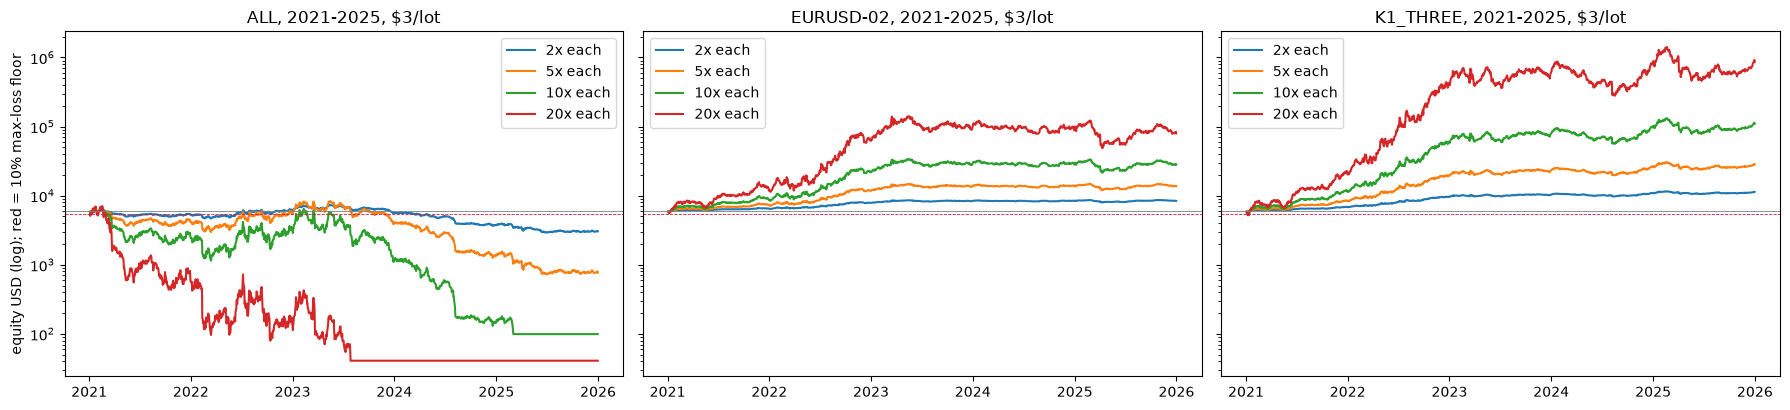

In [5]:
rows, curves = [], {}
for set_name, ids in SETS.items():
    for L in LEVERAGES:
        w = pd.Series(float(L), index=ids)
        acc = F.simulate_account(N_out[ids], w, E0)
        o, d, e = F.run_prop_path(G_out[ids].to_numpy(), M_out[ids].to_numpy(), comm[ids].to_numpy(), w.to_numpy(), E0, FUNDED, len(G_out), compound=False)
        curves[(set_name, L)] = acc
        st = F.account_stats(acc, E0)
        prev = acc["equity"].shift(1).fillna(E0).to_numpy()
        day_worst = ((np.floor(prev[:, None] * L / 1000) * 1000) * (M_out[ids].to_numpy() - comm[ids].to_numpy())).sum(axis=1) / 1e4
        worst_day = float((day_worst / np.maximum(prev, 1e-9)).min())
        rows.append({"set": set_name, "L_each": L, "max_notional_x": L * F.max_concurrent(cand[cand["id"].isin(ids)]),
                     **st, "worst_day_pct": worst_day, "prop_fixed_size_outcome": o, "prop_breach_day": d if o != "open" else None,
                     "prop_fixed_size_end_equity": e})
res = pd.DataFrame(rows)
show = res.copy()
for c in ("cagr", "ann_vol", "max_drawdown", "worst_year", "best_year", "worst_day_pct"):
    show[c] = (100 * show[c]).round(1).astype(str) + "%"
show["final_equity"] = show["final_equity"].round(0); show["prop_fixed_size_end_equity"] = show["prop_fixed_size_end_equity"].round(0)
display(show); res.to_csv(OUT / "04_account_growth.csv", index=False)
fig, axes = plt.subplots(1, len(SETS), figsize=(18, 4.2), sharey=True)
for ax, s in zip(axes, SETS):
    for L in LEVERAGES:
        ax.plot(curves[(s, L)]["equity"].clip(lower=1), label=f"{L}x each")
    ax.axhline(E0, color="grey", lw=0.6); ax.axhline(E0 * 0.9, color="crimson", ls="--", lw=0.6)
    ax.set_yscale("log"); ax.set_title(f"{s}, 2021-2025, $3/lot"); ax.legend()
axes[0].set_ylabel("equity USD (log); red = 10% max-loss floor")
plt.tight_layout(); plt.savefig(OUT / "04_account_growth.png", dpi=110); plt.show()

## 4. Challenge and funded-stage odds (bootstrap of 2021–2025 days)

5,000 paths per cell, drawing whole trading days (all structures of the same day together). Phase 1: 8% target; phase 2: 5%; funded: 12 months (252 days), no target. `open` = neither passed nor breached within the time allowed (120 trading days for the phases).

In [6]:
odds = []
for set_name, ids in SETS.items():
    for L in LEVERAGES:
        w = pd.Series(float(L), index=ids)
        for stage, rules, days in (("phase 1", PHASE1, 120), ("phase 2", PHASE2, 120), ("funded 12m", FUNDED, 252)):
            r = F.prop_odds(G_out[ids], M_out[ids], comm[ids], w, E0, rules, days, N_SIMS, SEED + L)
            odds.append({"set": set_name, "L_each": L, "stage": stage, **r})
odds = pd.DataFrame(odds)
display(odds.pivot_table(index=["set", "L_each"], columns="stage", values=["pass", "daily_breach", "max_breach"]).round(3))
display(odds[odds["stage"] == "funded 12m"][["set", "L_each", "daily_breach", "max_breach", "open", "median_end_equity"]].round(3))
odds.to_csv(OUT / "04_prop_odds.csv", index=False)

daily_breach                 max_breach                       pass                
stage              funded 12m phase 1 phase 2 funded 12m phase 1 phase 2 funded 12m phase 1 phase 2
set       L_each                                                                                   
ALL       2             0.807   0.588   0.472      0.191   0.185   0.171        0.0   0.219   0.355
          5             1.000   0.986   0.975      0.000   0.000   0.000        0.0   0.014   0.024
          10            1.000   1.000   1.000      0.000   0.000   0.000        0.0   0.000   0.000
          20            1.000   1.000   1.000      0.000   0.000   0.000        0.0   0.000   0.000
EURUSD-02 2             0.000   0.000   0.000      0.014   0.003   0.003        0.0   0.194   0.468
          5             0.166   0.047   0.036      0.170   0.131   0.122        0.0   0.659   0.777
          10            0.896   0.404   0.307      0.103   0.097   0.090        0.0   0.499   0.603
          20            0.986   0.747   0.699      0.014   0.013   0.013        0.0   0.240   0.288
K1_THREE  2             0.000   0.000   0.000      0.021   0.009   0.009        0.0   0.476   0.730
          5             0.755   0.245   0.171      0.098   0.095   0.085        0.0   0.640   0.738
          10            0.981   0.692   0.596      0.019   0.020   0.020        0.0   0.288   0.384
          20            1.000   0.966   0.962      0.000   0.000   0.000        0.0   0.034   0.038

,set,L_each,daily_breach,max_breach,open,median_end_equity
2,ALL,2,0.807,0.191,0.002,5619.979
5,ALL,5,1.000,0.000,0.000,5622.109
8,ALL,10,1.000,0.000,0.000,5406.145
11,ALL,20,1.000,0.000,0.000,4824.352
14,EURUSD-02,2,0.000,0.014,0.986,6419.640
17,EURUSD-02,5,0.166,0.170,0.663,6857.575
20,EURUSD-02,10,0.896,0.103,0.001,5937.730
23,EURUSD-02,20,0.986,0.014,0.000,5723.396
26,K1_THREE,2,0.000,0.021,0.979,6774.920
29,K1_THREE,5,0.755,0.098,0.147,6376.284


## 5. Contrast: the same odds on 2016–2020 (in sample, biased upward)

In [ ]:
odds_in = []
for set_name, ids in SETS.items():
    for L in LEVERAGES:
        r = F.prop_odds(G_in[ids], M_in[ids], comm[ids], pd.Series(float(L), index=ids), E0, PHASE1, 120, N_SIMS, SEED + L)
        odds_in.append({"set": set_name, "L_each": L, **r})
odds_in = pd.DataFrame(odds_in)
display(odds_in.pivot(index="L_each", columns="set", values="pass").round(3))
odds_in.to_csv(OUT / "04_prop_odds_in_sample.csv", index=False)

In [ ]:
summary = {"study": "FXS04", "post_hoc": True, "fxs_version": F.FXS_VERSION, "synthetic": SYNTHETIC, "equity0": E0,
           "commission_usd_per_lot_rt": COMMISSION_PER_LOT, "sets": SETS,
           "gates_at_3usd_per_lot": post[["id", "net_bps", "K1", "K2", "K3", "K4", "verdict"]].to_dict(orient="records"),
           "account_growth": res.to_dict(orient="records"), "prop_odds": odds.to_dict(orient="records"),
           "note": "Post hoc: cost model chosen after FXS 02. Sets EURUSD-02 and K1_THREE use 2021-2025 results to choose."}
(OUT / "summary.json").write_text(json.dumps(summary, indent=2, default=str))
print("written", OUT / "summary.json")